# Reproducing Logic-LM (Pan et al., Findings of EMNLP 2023)

Runs the authors' **symbolic-solver stage** on the logic programs **they** generated with GPT-4
(`outputs/logic_programs`), with 3 seeds. No OpenAI key and no GPU needed (`Runtime > Change runtime type > CPU` is fine).

Run the cells top to bottom. Every cell writes its full output to `logs/`.
**If a cell fails, do not delete it.** Write the error and your fix in `NOTES.md` (Attempt 1, 2, 3...) and re-run.

In [1]:
# 1. Your fork (change if your username differs)
GITHUB_USER = "suriyakala-gif"
REPO = "Logic-LLM"
!git clone https://github.com/{GITHUB_USER}/{REPO}.git
%cd {REPO}
!mkdir -p logs results

Cloning into 'Logic-LLM'...
remote: Enumerating objects: 959, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 959 (delta 48), reused 39 (delta 39), pack-reused 864 (from 1)
Receiving objects: 100% (959/959), 8.66 MiB | 4.32 MiB/s, done.
Resolving deltas: 100% (208/208), done.
/content/Logic-LLM


In [2]:
# 2. Record the environment for SETUP.md
!( date -u; echo; python --version; echo; cat /etc/os-release | head -2; echo; nproc; free -h | head -2; echo; nvidia-smi -L 2>/dev/null || echo "GPU: none (CPU runtime)" ) 2>&1 | tee logs/00_environment.log

Mon Nov  9 06:03:48 AM UTC 2026

Python 3.13.18

PRETTY_NAME="Ubuntu 24.04.5 LTS"
NAME="Ubuntu"

2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.2Gi       9.0Gi       2.2Mi       2.8Gi        11Gi

GPU: none (CPU runtime)


In [3]:
# 3. Install exactly as the README says. If this fails -> NOTES.md Attempt 1, then try the next cell.
!pip install -r requirements.txt 2>&1 | tee logs/01_install.log

Processing /croot/certifi_1671487769961/work/certifi (from -r requirements.txt (line 14))
ERROR: Could not install packages due to an OSError: [Errno 2] No such file or directory: '/croot/certifi_1671487769961/work/certifi'



In [4]:
# Attempt 2: remove the lines with local file paths, keep the versions
!grep -v "@ file://" requirements.txt > requirements_clean.txt
!wc -l requirements.txt requirements_clean.txt
!pip install -r requirements_clean.txt 2>&1 | tee logs/01b_install_attempt2.log | tail -15

 139 requirements.txt
 138 requirements_clean.txt
 277 total
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 81.1 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel: finished with status 'error'
ERROR: Failed to build 'blis' when getting requirements to build wheel


In [5]:
# Attempt 3: install only the packages the symbolic solvers need (no old version pins)
!pip install z3-solver python-constraint nltk tqdm pyke3 2>&1 | tee logs/01c_install_attempt3.log | tail -5

# Which modules does the authors' code import?
!grep -rhoE "^\s*(from|import) [a-zA-Z_0-9]+" models/*.py models/symbolic_solvers | awk '{print $2}' | sort -u | tr '\n' ' '
print()

# Test that each solver library loads
!python -c "import z3, constraint, nltk, tqdm; print('z3 / constraint / nltk / tqdm OK')"
!python -c "from pyke import knowledge_engine; print('pyke OK')"

  Preparing metadata (pyproject.toml): finished with status 'done'
ERROR: Could not find a version that satisfies the requirement pyke3 (from versions: none)
ERROR: No matching distribution found for pyke3
a an argparse asyncio backoff backup_answer_generation collections concurrent doctest enum f func_timeout json malloc nltk openai optparse os ply pyke random re sat_problem_solver shlex signal smaller socket string subprocess symbolic_solvers sys tempfile Terms textwrap the time tqdm typing utils xml z3 
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import z3, constraint, nltk, tqdm; print('z3 / constraint / nltk / tqdm OK')
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ModuleNotFoundError: No module named 'z3'
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from pyke import knowledge_engine; print('pyke OK')
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ModuleNotFoundError: No module named 'pyke'


In [6]:
# Attempt 4: install packages separately so one failure does not block the others
!pip install z3-solver python-constraint func_timeout 2>&1 | tee logs/01d_install_attempt4.log | tail -2
!python -c "import z3, constraint, nltk, tqdm, func_timeout; print('z3 / constraint / nltk / tqdm / func_timeout OK')"

# Find how the authors installed Pyke
!grep -i pyke requirements.txt
!find / -iname "*knowledge_engine*" -not -path "/proc/*" 2>/dev/null | head -3
!pip install pyke 2>&1 | tee -a logs/01d_install_attempt4.log | tail -2
!python -c "from pyke import knowledge_engine; print('pyke OK')"


z3 / constraint / nltk / tqdm / func_timeout OK
scitools-pyke==1.1.1
ERROR: Could not find a version that satisfies the requirement pyke (from versions: none)
ERROR: No matching distribution found for pyke
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from pyke import knowledge_engine; print('pyke OK')
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ModuleNotFoundError: No module named 'pyke'


In [7]:
# Attempt 5: install Pyke under the name the authors used
!pip install scitools-pyke==1.1.1 2>&1 | tee logs/01e_install_pyke.log | tail -2
!python -c "from pyke import knowledge_engine; print('pyke OK')" 2>&1 | tail -3

# If pyke fails because Python 3.13 removed the old 'imp' module, add it back:
!pip install zombie-imp 2>&1 | tail -1
!python -c "import zombie_imp; from pyke import knowledge_engine; print('pyke OK with zombie-imp')" 2>&1 | tail -3

  File "/usr/local/lib/python3.13/dist-packages/pyke/knowledge_engine.py", line 28, in <module>
    import imp
ModuleNotFoundError: No module named 'imp'
pyke OK with zombie-imp


In [8]:
# Load zombie_imp automatically in every Python run (no change to the authors' code)
import site, os
pth = os.path.join(site.getsitepackages()[0], "zombie_imp_autoload.pth")
open(pth, "w").write("import zombie_imp\n")
!python -c "from pyke import knowledge_engine; print('pyke OK automatically')"

pyke OK automatically


In [ ]:
# 3b. ONLY if 3 failed: install the solver packages without the old pins, and log it.
# !pip install z3-solver python-constraint nltk tqdm 2>&1 | tee logs/01b_install_fallback.log
# !pip install pyke3 2>&1 | tee -a logs/01b_install_fallback.log   # Pyke for ProntoQA/ProofWriter

In [9]:
# 4. Prover9 (needed for FOLIO). The repo ships a Linux binary; make sure it is executable.
!find . -path "*Prover9*" -name "prover9" -type f 2>/dev/null | tee logs/02_prover9.log
!find . -path "*Prover9*bin*" -type f -exec chmod +x {} \; 2>&1 | tee -a logs/02_prover9.log
# If FOLIO later fails with a Prover9 error, try the system package and note it in NOTES.md:
# !apt-get -y install prover9 2>&1 | tee -a logs/02_prover9.log

./models/symbolic_solvers/Prover9/bin/prover9
./models/symbolic_solvers/Prover9/provers.src/prover9


In [10]:
# 5. Which saved logic programs exist? (This decides which datasets you can reproduce.)
!ls -la outputs/logic_programs/ 2>&1 | tee logs/03_available_programs.log

total 11940
drwxr-xr-x 2 root root    4096 Nov  9 06:03 .
drwxr-xr-x 3 root root    4096 Nov  9 06:03 ..
-rw-r--r-- 1 root root  603632 Nov  9 06:03 AR-LSAT_dev_gpt-3.5-turbo.json
-rw-r--r-- 1 root root  605672 Nov  9 06:03 AR-LSAT_dev_gpt-4.json
-rw-r--r-- 1 root root  601618 Nov  9 06:03 AR-LSAT_dev_text-davinci-003.json
-rw-r--r-- 1 root root  347252 Nov  9 06:03 FOLIO_dev_gpt-3.5-turbo.json
-rw-r--r-- 1 root root  336907 Nov  9 06:03 FOLIO_dev_gpt-4.json
-rw-r--r-- 1 root root  326815 Nov  9 06:03 FOLIO_dev_text-davinci-003.json
-rw-r--r-- 1 root root  549964 Nov  9 06:03 LogicalDeduction_dev_gpt-3.5-turbo.json
-rw-r--r-- 1 root root  547855 Nov  9 06:03 LogicalDeduction_dev_gpt-4.json
-rw-r--r-- 1 root root  548133 Nov  9 06:03 LogicalDeduction_dev_text-davinci-003.json
-rw-r--r-- 1 root root 1040277 Nov  9 06:03 ProntoQA_dev_gpt-3.5-turbo.json
-rw-r--r-- 1 root root 1014637 Nov  9 06:03 ProntoQA_dev_gpt-4.json
-rw-r--r-- 1 root root 1051296 Nov  9 06:03 ProntoQA_dev_text-davinci-

In [12]:
# Attempt 6 fix: missing parser package + output folder name
!pip install ply 2>&1 | tee logs/01f_install_ply.log | tail -1
!python -c "import ply; print('ply OK')"
!sed -i 's|"logic_inferences"|"logic_inference*"|' run_reproduction.py
!grep -n 'logic_inference\*' run_reproduction.py

ply OK
70:    pattern = os.path.join("outputs", "logic_inference*", f"*{dataset}*{split}*{model}*.json")


In [13]:
# 6. One run EXACTLY as the README shows, to prove the authors' command works as written.
!python models/logic_inference.py \
    --model_name gpt-4 --dataset_name FOLIO --split dev \
    --backup_strategy random \
    --backup_LLM_result_path ./baselines/results/CoT_FOLIO_dev_gpt-4.json 2>&1 | tee logs/04_readme_command_FOLIO.log
!python models/evaluation.py --dataset_name FOLIO --model_name gpt-4 --split dev --backup random 2>&1 | tee -a logs/04_readme_command_FOLIO.log

/content/Logic-LLM/models/symbolic_solvers/fol_solver/fol_parser.py:91: SyntaxWarning: invalid escape sequence '\w'
  NOTE: since nltk does not support reg strs like \w+, we cannot separately recognize VAR, PRED, and CONST.
Loaded 204 examples from dev split.
 32%|███▏      | 66/204 [00:20<00:10, 12.86it/s]Traceback (most recent call last):
  File "/content/Logic-LLM/models/evaluation.py", line 120, in <module>
    full_evaluation(result_file)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^
  File "/content/Logic-LLM/models/evaluation.py", line 97, in full_evaluation
    with open(result_file, 'r') as f:
         ~~~~^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: './outputs/logic_inference/FOLIO_dev_gpt-4_backup-random.json'


In [14]:
# Diagnose: why did FOLIO inference stop at 66/204?
!python models/logic_inference.py --model_name gpt-4 --dataset_name FOLIO --split dev --backup_strategy random --backup_LLM_result_path ./baselines/results/CoT_FOLIO_dev_gpt-4.json > logs/04b_FOLIO_diagnose.log 2>&1; echo "exit code: $?"
!tail -c 2500 logs/04b_FOLIO_diagnose.log
!ls outputs/

/bin/bash: line 1:  5995 Killed                  python models/logic_inference.py --model_name gpt-4 --dataset_name FOLIO --split dev --backup_strategy random --backup_LLM_result_path ./baselines/results/CoT_FOLIO_dev_gpt-4.json > logs/04b_FOLIO_diagnose.log 2>&1
exit code: 137
Loaded 204 examples from dev split.
 33%|███▎      | 68/204 [00:20<00:05, 22.87it/s]logic_programs


In [15]:
# Attempt 7 fix: limit memory to ~4 GB so one runaway problem cannot crash the run
!ulimit -v 4000000; python models/logic_inference.py --model_name gpt-4 --dataset_name FOLIO --split dev --backup_strategy random --backup_LLM_result_path ./baselines/results/CoT_FOLIO_dev_gpt-4.json > logs/04c_FOLIO_memlimit.log 2>&1; echo "exit code: $?"
!tail -c 800 logs/04c_FOLIO_memlimit.log
!python models/evaluation.py --dataset_name FOLIO --model_name gpt-4 --split dev --backup random 2>&1 | tee -a logs/04c_FOLIO_memlimit.log

exit code: 0
100%|██████████| 204/204 [00:37<00:00,  5.51it/s]
Error count: 43
Overall accuracy: 0.7156862745098039
Executable rate (Exe_Rate): 0.7892156862745098
Executable accuracy (Exe_Acc): 0.8074534161490683


In [ ]:
# 7. Full reproduction: 5 datasets x 3 seeds -> results/my_results.csv + logs/inference_*.log
!python run_reproduction.py --seeds 0 1 2 --split dev --model gpt-4 2>&1 | tee logs/05_reproduction.log
!cat results/my_results.csv

In [16]:
# 7 (with memory limit): full reproduction, 5 datasets x 3 seeds
!ulimit -v 4000000; python run_reproduction.py --seeds 0 1 2 --split dev --model gpt-4 2>&1 | tee logs/05_reproduction.log
!cat results/my_results.csv

[run] ProntoQA seed=0
      -> acc=83.20%  exec_rate=100.00%  n=500  (14s)
[run] ProntoQA seed=1
      -> acc=83.20%  exec_rate=100.00%  n=500  (14s)
[run] ProntoQA seed=2
      -> acc=83.20%  exec_rate=100.00%  n=500  (14s)
[run] ProofWriter seed=0
      -> acc=79.67%  exec_rate=99.00%  n=600  (13s)
[run] ProofWriter seed=1
      -> acc=79.50%  exec_rate=99.00%  n=600  (13s)
[run] ProofWriter seed=2
      -> acc=79.33%  exec_rate=99.00%  n=600  (13s)
[run] FOLIO seed=0
      -> acc=70.10%  exec_rate=78.92%  n=204  (31s)
[run] FOLIO seed=1
      -> acc=74.02%  exec_rate=78.92%  n=204  (31s)
[run] FOLIO seed=2
      -> acc=74.02%  exec_rate=79.90%  n=204  (44s)
[run] LogicalDeduction seed=0
      -> FAILED (exit_1); see logs/inference_LogicalDeduction_seed0.log
[run] LogicalDeduction seed=1
      -> FAILED (exit_1); see logs/inference_LogicalDeduction_seed1.log
[run] LogicalDeduction seed=2
      -> FAILED (exit_1); see logs/inference_LogicalDeduction_seed2.log
[run] AR-LSAT seed=0
    

### Before the next cell
Open `results/paper_values.csv` (Files panel, left) and type in the paper's **Logic-LM (GPT-4)** accuracy for each dataset,
copied from the main results table in the paper PDF. Save the file.

In [17]:
# Paper values: Table 2 (GPT-4, Logic-LM without self-refinement), Pan et al. 2023
open("results/paper_values.csv", "w").write("""dataset,paper_accuracy,note
ProntoQA,83.20,
ProofWriter,79.66,
FOLIO,78.92,
LogicalDeduction,87.63,
AR-LSAT,43.04,
""")
!cat results/paper_values.csv

# Why did LogicalDeduction fail?
!tail -25 logs/inference_LogicalDeduction_seed0.log

# Did the authors save their CoT answers (the paper's backup)?
!ls baselines/results/ | head -30

dataset,paper_accuracy,note
ProntoQA,83.20,
ProofWriter,79.66,
FOLIO,78.92,
LogicalDeduction,87.63,
AR-LSAT,43.04,
$ /usr/bin/python3 -c <wrapper> 0 --model_name gpt-4 --dataset_name LogicalDeduction --split dev --backup_strategy random --backup_LLM_result_path ./baselines/results/CoT_LogicalDeduction_dev_gpt-4.json

Loaded 299 examples from dev split.
  0%|          | 0/299 [00:00<?, ?it/s]
Traceback (most recent call last):
  File "<string>", line 12, in <module>
    runpy.run_path("models/logic_inference.py", run_name="__main__")
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen runpy>", line 294, in run_path
  File "<frozen runpy>", line 98, in _run_module_code
  File "<frozen runpy>", line 88, in _run_code
  File "models/logic_inference.py", line 103, in <module>
    engine.inference_on_dataset()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "models/logic_inference.py", line 65, in inference_on_dataset
    answer, flag, error_message = self.safe_execu

In [18]:
!sed -n 1,35p models/backup_answer_generation.py
!echo ----------
!sed -n 38,60p models/logic_inference.py
!echo ----------
!grep -n "class \|def \|import" models/symbolic_solvers/csp_solver/*.py

import json
import random
import os

class Backup_Answer_Generator:
    def __init__(self, dataset_name, backup_strategy, backup_LLM_result_path) -> None:
        self.dataset_name = dataset_name
        self.backup_strategy = backup_strategy
        self.backup_LLM_result_path = backup_LLM_result_path
        if self.backup_strategy == 'LLM':
            with open(backup_LLM_result_path, 'r') as f:
                LLM_result = json.load(f)
            self.backup_results = {sample['id'] : sample['predicted_answer'] for sample in LLM_result}

    def get_backup_answer(self, id):
        if self.backup_strategy == 'random':
            return self.random_backup()
        elif self.backup_strategy == 'LLM':
            return self.LLM_backup(id)
        
    def random_backup(self):
        if self.dataset_name == 'ProntoQA':
            return random.choice(['A', 'B'])
        elif self.dataset_name == 'ProofWriter' or self.dataset_name == 'FOLIO':
            return random.choice(['A',

In [19]:
# Diagnose: run the authors' CSP solver directly on all 299 LogicalDeduction programs
import sys, json
sys.path.insert(0, "models")
from symbolic_solvers.csp_solver.csp_solver import CSP_Program

data = json.load(open("outputs/logic_programs/LogicalDeduction_dev_gpt-4.json"))
ok, errors, first = 0, {}, None
for ex in data:
    p = CSP_Program(ex["raw_logic_programs"][0].strip(), "LogicalDeduction")
    if not p.flag:
        msg = "parsing error"
    else:
        ans, err = p.execute_program()
        if ans is not None:
            ok += 1
            continue
        msg = str(err)[:200]
    errors[msg] = errors.get(msg, 0) + 1
    if first is None:
        first = (ex["id"], msg)

print("Executed OK:", ok, "of", len(data))
print("First failure:", first)
for m, c in sorted(errors.items(), key=lambda x: -x[1])[:5]:
    print(c, "x", m)

Executed OK: 0 of 299
First failure: ('logical_deduction_0', '')
299 x 


In [20]:
!sed -n 35,56p models/symbolic_solvers/csp_solver/csp_solver.py
!echo ----------
!sed -n 83,113p models/symbolic_solvers/csp_solver/csp_solver.py
!echo ---------- DEBUG RUN ON FIRST PROGRAM ----------
p = CSP_Program(data[0]["raw_logic_programs"][0].strip(), "LogicalDeduction")
print("parsed:", p.flag)
print(p.execute_program(debug_mode=True))

    def safe_execute(self, code_string: str, keys = None, debug_mode = False):
        def execute(x):
            try:
                exec(x)
                locals_ = locals()
                if keys is None:
                    return locals_.get('ans', None), ""
                else:
                    return [locals_.get(k, None) for k in keys], ""
            except Exception as e:
                if debug_mode:
                    print(e)
                return None, e
        try:
            ans, error_msg = func_timeout.func_timeout(self.timeout, execute, args=(code_string,))
        except func_timeout.FunctionTimedOut:
            ans = None
            error_msg = "timeout"

        return ans, error_msg

    # comparison (>, <), fixed value (==, !=), etc
----------
    def execute_program(self, debug_mode = False):
        # parse the logic program into CSP python program
        python_program_list = ['from constraint import *', 'problem = Problem()']
        # add va

In [21]:
# Attempt 9 fix: make the CSP solver work on Python 3.13 (documented change to the authors' code)
f = "models/symbolic_solvers/csp_solver/csp_solver.py"
src = open(f).read()
old = "                exec(x)\n                locals_ = locals()\n"
new = "                locals_ = {}  # Python 3.13 fix (PEP 667): exec into an explicit dict\n                exec(x, globals(), locals_)\n"
assert old in src, "pattern not found - send a screenshot"
open(f, "w").write(src.replace(old, new))
print("patched")

# Test on the first program again
import importlib, symbolic_solvers.csp_solver.csp_solver as m
importlib.reload(m)
p = m.CSP_Program(data[0]["raw_logic_programs"][0].strip(), "LogicalDeduction")
print(p.execute_program())

# Keep the first run as evidence, then re-run all 5 datasets x 3 seeds with the fix
!cp results/my_results.csv results/my_results_run1_before_fix.csv
!ulimit -v 4000000; python run_reproduction.py --seeds 0 1 2 --split dev --model gpt-4 2>&1 | tee logs/06_reproduction_after_fix.log

patched
([{'yellow_book': 3, 'blue_book': 4, 'white_book': 1, 'purple_book': 2, 'green_book': 5}], '')
[run] ProntoQA seed=0
      -> acc=83.20%  exec_rate=100.00%  n=500  (14s)
[run] ProntoQA seed=1
      -> acc=83.20%  exec_rate=100.00%  n=500  (14s)
[run] ProntoQA seed=2
      -> acc=83.20%  exec_rate=100.00%  n=500  (14s)
[run] ProofWriter seed=0
      -> acc=79.67%  exec_rate=99.00%  n=600  (13s)
[run] ProofWriter seed=1
      -> acc=79.50%  exec_rate=99.00%  n=600  (13s)
[run] ProofWriter seed=2
      -> acc=79.33%  exec_rate=99.00%  n=600  (13s)
[run] FOLIO seed=0
      -> acc=69.12%  exec_rate=79.90%  n=204  (44s)
[run] FOLIO seed=1
      -> acc=74.02%  exec_rate=78.92%  n=204  (31s)
[run] FOLIO seed=2
      -> acc=74.02%  exec_rate=79.90%  n=204  (42s)
[run] LogicalDeduction seed=0
      -> acc=87.63%  exec_rate=100.00%  n=299  (3s)
[run] LogicalDeduction seed=1
      -> acc=87.63%  exec_rate=100.00%  n=299  (3s)
[run] LogicalDeduction seed=2
      -> acc=87.63%  exec_rate=100

AR-LSAT Exe_Acc = 60.00%  (75/230 executed)
FOLIO Exe_Acc = 80.37%  (163/204 executed)
LogicalDeduction Exe_Acc = 87.63%  (299/299 executed)
ProntoQA Exe_Acc = 83.20%  (500/500 executed)
ProofWriter Exe_Acc = 79.63%  (594/600 executed)
ProntoQA          paper=  83.2  mine= 83.20 +/- 0.00  diff=  +0.0%  exec=100.0  Reproduced
ProofWriter       paper= 79.66  mine= 79.50 +/- 0.17  diff=  -0.2%  exec= 99.0  Reproduced
FOLIO             paper= 78.92  mine= 72.39 +/- 2.83  diff=  -8.3%  exec= 79.6  Partly
LogicalDeduction  paper= 87.63  mine= 87.63 +/- 0.00  diff=  +0.0%  exec=100.0  Reproduced
AR-LSAT           paper= 43.04  mine= 32.75 +/- 2.66  diff= -23.9%  exec= 32.6  Not reproduced

Wrote results/summary.csv and results/table1.tex
Wrote fig1.pdf
Wrote fig1_gray.png (grayscale check)


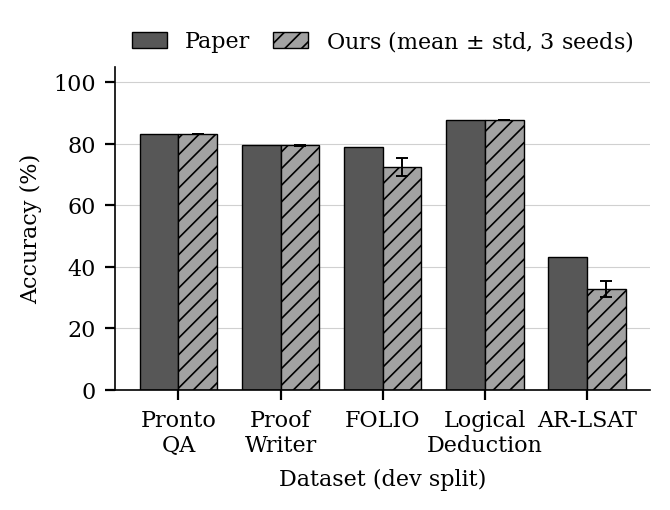

func_timeout==4.3.5
nltk==3.9.1
ply==3.11
python-constraint==1.4.0
scitools-pyke==1.1.1
tqdm==4.67.3
z3-solver==5.3.3.0
zombie-imp==0.0.4


In [22]:
# Short notes for the report table
open("results/paper_values.csv", "w").write("""dataset,paper_accuracy,note
ProntoQA,83.20,Exact; all programs run
ProofWriter,79.66,Within 1%
FOLIO,78.92,Random backup (paper: CoT)
LogicalDeduction,87.63,After Python 3.13 fix
AR-LSAT,43.04,Random backup (paper: CoT)
""")

# Accuracy on executed programs only (compare with paper Table 3, Exe_Acc)
import json, glob, csv
rows = []
for f in sorted(glob.glob("results/raw/*_seed0.json")):
    recs = json.load(open(f)); ds = recs and f.split("/")[-1].split("_dev")[0]
    ex = [r for r in recs if r.get("flag") == "success"]
    acc = 100 * sum(str(r["answer"]).strip() == str(r["predicted_answer"]).strip() for r in ex) / len(ex)
    rows.append((ds, len(ex), len(recs), round(acc, 2))); print(ds, f"Exe_Acc = {acc:.2f}%  ({len(ex)}/{len(recs)} executed)")
csv.writer(open("results/exec_accuracy_seed0.csv", "w")).writerows([("dataset", "executed", "total", "exe_acc")] + rows)

# Table + figure
!python make_table.py 2>&1 | tee logs/07_table.log
!python make_figure.py --gray 2>&1 | tee logs/08_figure.log
from IPython.display import Image, display
display(Image("fig1_gray.png"))

# Package versions: the solver packages I used (requirements.txt) + full Colab freeze
!cp requirements.txt requirements_original.txt
!pip freeze > requirements_full_colab_freeze.txt
!grep -i -E "^(z3-solver|python-constraint|func.timeout|scitools-pyke|zombie-imp|ply|nltk|tqdm)==" requirements_full_colab_freeze.txt > requirements.txt
!cat requirements.txt

In [23]:
!zip -r reproduction_outputs.zip logs results fig1.pdf fig1_gray.png requirements.txt requirements_original.txt requirements_full_colab_freeze.txt run_reproduction.py models/symbolic_solvers/csp_solver/csp_solver.py
from google.colab import files
files.download("reproduction_outputs.zip")

  adding: logs/ (stored 0%)
  adding: logs/inference_ProofWriter_seed1.log (deflated 97%)
  adding: logs/04b_FOLIO_diagnose.log (deflated 72%)
  adding: logs/03_available_programs.log (deflated 78%)
  adding: logs/01c_install_attempt3.log (deflated 54%)
  adding: logs/inference_AR-LSAT_seed2.log (deflated 81%)
  adding: logs/inference_LogicalDeduction_seed2.log (deflated 42%)
  adding: logs/inference_FOLIO_seed1.log (deflated 72%)
  adding: logs/inference_FOLIO_seed0.log (deflated 73%)
  adding: logs/04_readme_command_FOLIO.log (deflated 63%)
  adding: logs/01e_install_pyke.log (deflated 45%)
  adding: logs/04c_FOLIO_memlimit.log (deflated 75%)
  adding: logs/01d_install_attempt4.log (deflated 67%)
  adding: logs/inference_LogicalDeduction_seed0.log (deflated 45%)
  adding: logs/inference_ProntoQA_seed1.log (deflated 97%)
  adding: logs/02_prover9.log (deflated 46%)
  adding: logs/inference_ProofWriter_seed0.log (deflated 97%)
  adding: logs/00_environment.log (deflated 36%)
  adding: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 8. Comparison table + figure
!python make_table.py 2>&1 | tee logs/06_table.log
!python make_figure.py --gray 2>&1 | tee logs/07_figure.log
from IPython.display import Image, display
display(Image("fig1_gray.png"))   # grayscale check (Step 3)

In [ ]:
# 9. Freeze package versions (Step 1) - overwrites the authors' requirements.txt; the original stays in git history.
!cp requirements.txt requirements_original.txt
!pip freeze > requirements.txt

In [ ]:
# 10. Download everything you need to commit to GitHub
!zip -r reproduction_outputs.zip logs results fig1.pdf fig1_gray.png requirements.txt requirements_original.txt
from google.colab import files
files.download("reproduction_outputs.zip")